# Negative Review Guard — EDA, качество данных и моделирование
**Тема:** Реализация системы прогнозирования негативных отзывов покупателей и автоматизированного выбора мер по их предотвращению.

**Данные:** CORGIS *Video Games* (1212 игр, 2004–2008, 5 платформ) — открытый датасет. Целевая переменная:
*негативный отзыв* = оценка критиков `Metrics.Review Score` **< 60**.

**Бизнес-постановка:** издатель до релиза оценивает риск провала у критиков и выбирает меры (QA, плейтест, контент, перенос релиза), окупающиеся по ожидаемой выгоде.

> RO: Sistem de prognozare a recenziilor negative și selecție automată a măsurilor de prevenire.
> EN: System for predicting negative reviews and automatically selecting preventive measures.

In [1]:
import os, sys, json
sys.path.insert(0, os.path.abspath('..'))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from nrg import config, db, quality
pd.set_option('display.max_columns', 50)
if not config.DB_PATH.exists():
    db.init_db()
games = db.load_games()            # загрузка из SQLite (таблица games)
games.shape

(1212, 37)

## 1. Подключение к БД и первичный осмотр

In [2]:
games.head(3).T.head(20)

,0,1,2
game_id,1,2,3
title,Super Mario 64 DS,Lumines: Puzzle Fusion,WarioWare Touched!
features_handheld,1,1,1
features_max_players,1,1,2
features_multiplatform,1,1,1
features_online,1,1,1
metadata_genres,Action,Strategy,"Action,Racing / Driving,Sports"
metadata_licensed,1,1,1
metadata_publishers,Nintendo,Ubisoft,Nintendo
metadata_sequel,1,1,1


In [3]:
games.describe().T[['mean','std','min','50%','max']].round(2)

,mean,std,min,50%,max
game_id,606.50,350.02,1.00,606.50,1212.00
features_handheld,1.00,0.00,1.00,1.00,1.00
features_max_players,1.66,1.20,1.00,1.00,8.00
features_multiplatform,1.00,0.00,1.00,1.00,1.00
features_online,1.00,0.00,1.00,1.00,1.00
metadata_licensed,1.00,0.00,1.00,1.00,1.00
metadata_sequel,1.00,0.00,1.00,1.00,1.00
metrics_review_score,68.83,12.96,19.00,70.00,98.00
metrics_sales,0.50,1.07,0.01,0.21,14.66
metrics_used_price,17.39,5.02,4.95,17.95,49.95


## 2. Проверка качества данных

In [4]:
rep = quality.run_quality_checks(games)
pd.DataFrame(rep['issues'])[['severity','check','detail','decision']]

,severity,check,detail,decision
0,medium,missing_values,metadata_publishers: 264 missing (21.8%),Publisher -> category 'Unknown'
1,info,duplicates,304 titles appear on several consoles (not tru...,Use as feature n_platforms
2,high,constant_column,features_handheld has a single value (np.int64...,"Drop; re-derive (handheld from console, multip..."
3,high,constant_column,features_multiplatform has a single value (np....,"Drop; re-derive (handheld from console, multip..."
4,high,constant_column,features_online has a single value (np.int64(1...,"Drop; re-derive (handheld from console, multip..."
5,high,constant_column,metadata_licensed has a single value (np.int64...,"Drop; re-derive (handheld from console, multip..."
6,high,constant_column,metadata_sequel has a single value (np.int64(1...,"Drop; re-derive (handheld from console, multip..."
7,high,constant_column,release_re_release has a single value (np.int6...,"Drop; re-derive (handheld from console, multip..."
8,medium,zero_as_missing,length_main_story_median == 0 for 306 games (2...,"Replace 0 by NaN, median imputation inside the..."
9,low,outliers,30 extreme main-story lengths (>3 IQR),keep (RPGs are long by nature); trees are robu...


**Выводы по качеству:**
* 6 булевых признаков (`Handheld?`, `Multiplatform?`, `Online?`, `Licensed?`, `Sequel?`, `Re-release?`) **константны (всегда True)** — известная ошибка CORGIS. Удаляем и **восстанавливаем**: handheld из платформы, multiplatform из повторов названия на разных консолях, sequel — регулярным выражением по названию (цифры, римские числа, '08).
* 21.8% издателей пропущено → категория `Unknown`.
* Длина игры = 0 у 25% игр — это «нет данных», а не 0 часов.

## 3. EDA: целевая переменная

Доля негативных: 0.228


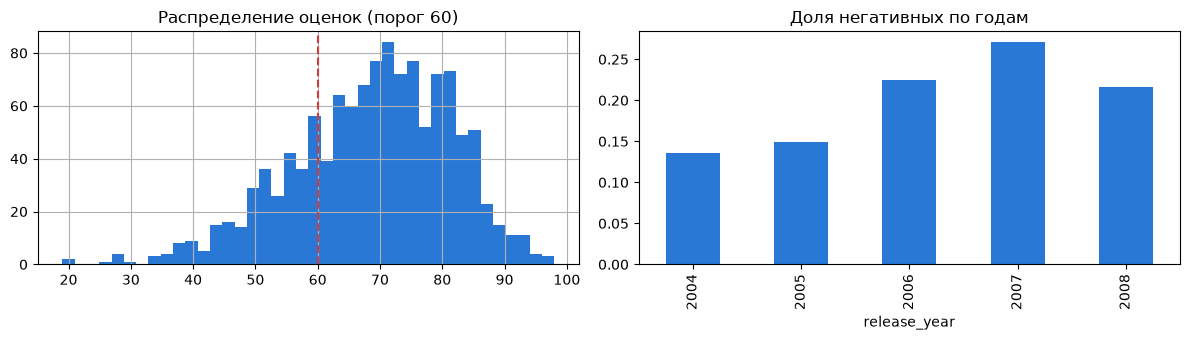

In [5]:
games['negative'] = (games.metrics_review_score < config.NEGATIVE_THRESHOLD).astype(int)
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
games.metrics_review_score.hist(bins=40, ax=ax[0], color='#2a78d6'); ax[0].axvline(60, color='#d03b3b', ls='--')
ax[0].set_title('Распределение оценок (порог 60)')
games.groupby('release_year').negative.mean().plot.bar(ax=ax[1], color='#2a78d6'); ax[1].set_title('Доля негативных по годам')
plt.tight_layout(); print('Доля негативных:', round(games.negative.mean(), 3))

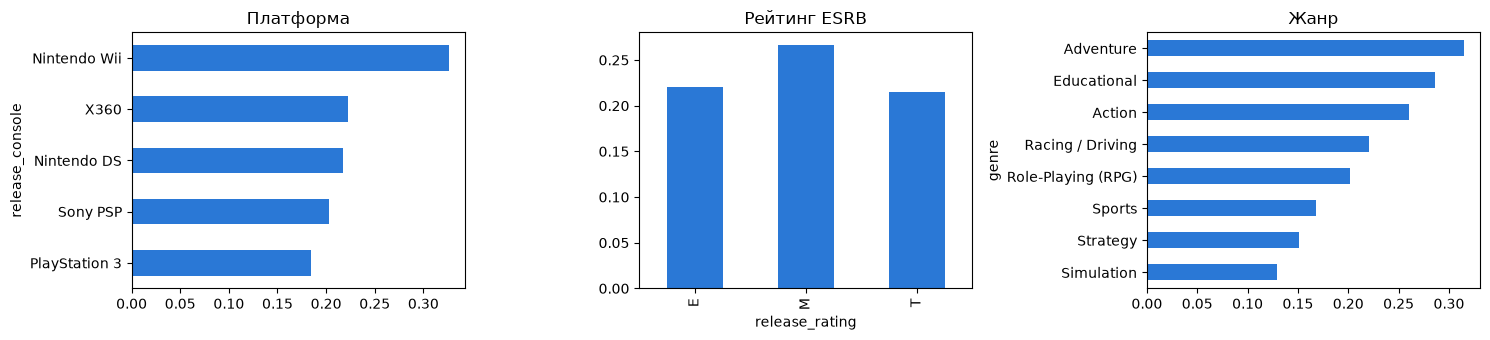

In [6]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.5))
games.groupby('release_console').negative.mean().sort_values().plot.barh(ax=ax[0], color='#2a78d6'); ax[0].set_title('Платформа')
games.groupby('release_rating').negative.mean().plot.bar(ax=ax[1], color='#2a78d6'); ax[1].set_title('Рейтинг ESRB')
g = games.assign(genre=games.metadata_genres.str.split(',')).explode('genre')
g.groupby('genre').negative.mean().sort_values().plot.barh(ax=ax[2], color='#2a78d6'); ax[2].set_title('Жанр')
plt.tight_layout()

## 4. Бизнес-цена негативного отзыва

           mean  median
negative               
0         0.582    0.26
1         0.237    0.11


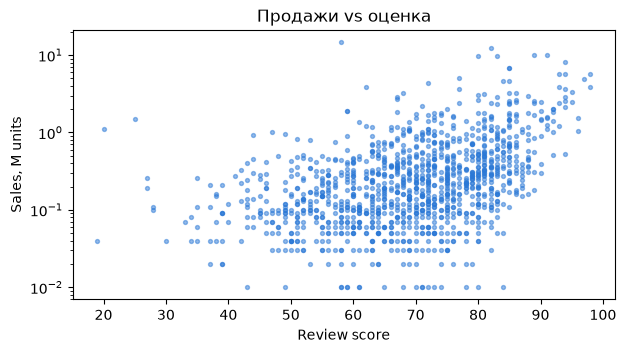

In [7]:
print(games.groupby('negative').metrics_sales.agg(['mean','median']).round(3))
plt.figure(figsize=(7,3.5)); plt.scatter(games.metrics_review_score, games.metrics_sales, s=8, alpha=.5, c='#2a78d6')
plt.yscale('log'); plt.xlabel('Review score'); plt.ylabel('Sales, M units'); plt.title('Продажи vs оценка');

Медианные продажи игр с негативными отзывами в ~2.4 раза ниже → «выручка под риском» используется агентом для оценки окупаемости мер.
**Но продажи известны только после релиза** — в признаки модели не входят (утечка).

## 5. Аудит утечки данных (leakage)

In [8]:
m = games.length_main_story_median == 0
pd.DataFrame({'neg_rate': [games.negative[m].mean(), games.negative[~m].mean()], 'n': [m.sum(), (~m).sum()]},
             index=['длина неизвестна', 'длина известна']).round(3)

,neg_rate,n
длина неизвестна,0.31,306
длина известна,0.20,906


**Важная находка:** если длина игры неизвестна (никто не прошёл её на HowLongToBeat), доля провалов 31% против 20%.
Это сигнал *непопулярности после релиза* → утечка. Решение: обучаемся только на играх с известной длиной (906),
а в форме для новой игры плановая длина — обязательное поле. Поля `Sales`, `Used Price`, `*.Polled` исключены.

## 6. Признаки и time-based split

In [9]:
from nrg.features import games_to_specs, history_from_games, build_features, FEATURE_COLS
history = history_from_games(games)
specs = games_to_specs(games)
known = (games.length_main_story_median > 0).values
X = build_features(specs[known].reset_index(drop=True), history)
y = games.negative[known].values
print(len(FEATURE_COLS), 'признаков'); X.head()

26 признаков


,main_story_hours,release_year,max_players,n_platforms,n_genres,n_publishers,pub_prior_mean_score,pub_prior_neg_rate,pub_prior_n_games,handheld,is_multiplayer,is_multiplatform,is_sequel,has_subtitle,publisher_unknown,genre_action,genre_sports,genre_strategy,genre_role_playing_rpg,genre_racing_driving,genre_simulation,genre_adventure,genre_educational,console,rating,publisher_main
0,14.500000,2004,1,1,1,1,70.0,0.2,0,1,0,0,0,0,0,1,0,0,0,0,0,0,0,Nintendo DS,E,Nintendo
1,10.000000,2004,1,1,1,1,70.0,0.2,0,1,0,0,0,1,0,0,0,1,0,0,0,0,0,Sony PSP,E,Ubisoft
2,1.833333,2004,2,1,3,1,70.0,0.2,0,1,1,0,0,0,0,1,1,0,0,1,0,0,0,Nintendo DS,E,Nintendo
3,8.000000,2004,1,2,1,1,70.0,0.2,0,1,0,1,1,0,0,1,0,0,0,0,0,0,0,Nintendo DS,E,Activision
4,15.500000,2004,1,1,1,1,70.0,0.2,0,1,0,0,0,1,0,0,0,0,0,0,1,0,0,Nintendo DS,M,EA


`pub_prior_*` — репутация издателя, посчитанная **только по играм прошлых лет** (Bayesian smoothing), без утечки.
Train: 2004–2007, Test: 2008 (модель проверяется «на будущем»).

## 7. Сравнение моделей (результаты `python -m nrg.train`)

In [10]:
comp = pd.read_json(config.ARTIFACTS_DIR / 'model_comparison.json')
comp[['model','cv_pr_auc','cv_roc_auc','test_pr_auc','test_roc_auc','test_f1','test_recall','test_precision']].round(3)

,model,cv_pr_auc,cv_roc_auc,test_pr_auc,test_roc_auc,test_f1,test_recall,test_precision
0,Baseline (majority),0.208,0.496,0.177,0.500,0.000,0.00,0.000
1,Logistic Regression,0.355,0.667,0.333,0.647,0.364,0.48,0.293
2,Random Forest,0.439,0.688,0.367,0.714,0.382,0.58,0.284
3,LightGBM,0.410,0.679,0.342,0.708,0.395,0.70,0.276
4,XGBoost,0.441,0.694,0.385,0.703,0.395,0.62,0.290


Выбор модели — по **PR-AUC на кросс-валидации** (а не на тесте, чтобы не подгонять под тест). PR-AUC выбран, т.к. классы
несбалансированы (≈21% негативных). Все модели в ~2 раза лучше базовой линии (PR-AUC 0.18).
Вероятности калибруются (Platt) — они нужны модулю решений для расчёта ожидаемой выгоды.

## 8. Explainable AI: SHAP

D:\Univer-Masterat\Machine-Learning\negative-review-guard\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


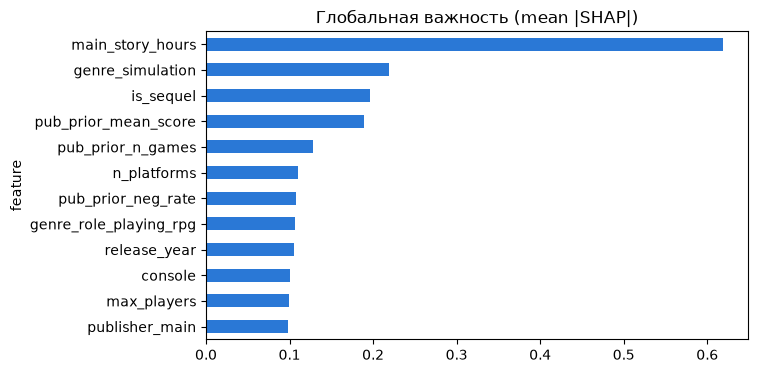

In [11]:
from nrg.predict import Predictor
P = Predictor()
imp = P.explainer.global_importance(X)
imp.head(12).iloc[::-1].plot.barh(x='feature', y='mean_abs_shap', figsize=(7,4), color='#2a78d6', legend=False)
plt.title('Глобальная важность (mean |SHAP|)');

In [12]:
# Локальное объяснение одного прогноза
spec = {'title': 'Galactic Racer 2', 'console': 'Nintendo Wii', 'year': 2009, 'rating': 'E', 'genres': 'Racing / Driving',
        'publisher': 'THQ', 'max_players': 1, 'main_story_hours': 4, 'n_platforms': 1, 'is_sequel': True}
r = P.predict(spec, save=False)
print('P(negative) =', round(r['proba_negative'], 3), '| risk:', r['risk_level'])
pd.DataFrame(r['explanation']['factors'])

P(negative) = 0.244 | risk: high


,feature,value,shap,direction
0,is_sequel,1,-0.848053,decreases_risk
1,main_story_hours,4,0.750814,increases_risk
2,console,Nintendo Wii,0.189220,increases_risk
3,pub_prior_n_games,61,-0.171689,decreases_risk
4,n_platforms,1,-0.119274,decreases_risk
5,pub_prior_mean_score,67.00215,0.116957,increases_risk
6,genre_simulation,0,0.074329,increases_risk
7,rating,E,-0.071395,decreases_risk


## 9. От прогноза к действию: модуль решений

In [13]:
from nrg.actions import evaluate_measures
ev = evaluate_measures(P, spec, r['proba_negative'])
print('Выручка под риском, k$:', round(ev['revenue_at_risk_k']), '| план:', ev['recommended_plan'])
pd.DataFrame(ev['measures'])[['code','kind','cost_k','p_after','expected_benefit_k','net_value_k','requires_approval']].round(3)

Выручка под риском, k$: 10600 | план: ['DELAY_RELEASE_POLISH', 'EXTENDED_QA', 'PLAYTEST_FOCUS_GROUP']


,code,kind,cost_k,p_after,expected_benefit_k,net_value_k,requires_approval
0,DELAY_RELEASE_POLISH,assumption,300,0.183,646.602,346.602,True
1,EXTENDED_QA,assumption,60,0.207,387.961,327.961,False
2,PLAYTEST_FOCUS_GROUP,assumption,25,0.220,258.641,233.641,False
3,EXTEND_CONTENT,simulated,180,0.206,402.030,222.030,True
4,CRITIC_PREVIEW_PR,assumption,15,0.232,129.320,114.320,False
5,ADD_MULTIPLAYER,simulated,120,0.237,71.747,-48.253,True
6,MULTIPLATFORM_PORT,simulated,250,0.253,-91.761,-341.761,True


Меры типа *simulated* оцениваются **самой моделью** (what-if: меняем признак и пересчитываем вероятность),
меры типа *assumption* — экспертное допущение об относительном снижении риска. Дорогие меры (>100 k$ или перенос релиза)
уходят на согласование менеджеру (Human-in-the-loop) через n8n.

Далее: AI-агент (`nrg/agent.py`), веб-приложение (`app/streamlit_app.py`), API (`api/main.py`), n8n (`n8n/nrg_workflow.json`).